# Mpox (MPXV) — host, composition and time

---

### Why this virus

Mpox was suggested as another virus with an animal-to-human story. It is a **double-stranded DNA virus** with a ~197 kb genome (RSV and Nipah are RNA viruses of 15-18 kb), and human-adapted mpox mutates mainly through the host **APOBEC3** enzymes, which turn C into T (usually after a T: TC to TT). That is a different mechanism from the CpG pressure studied in RSV, so the questions here are:

1. Does the host field offer a real contrast?
2. Is mpox CpG-suppressed like the RNA viruses?
3. Does the APOBEC3 signature show up as a falling GC or TpC over time?

### The data

GISAID EpiPox export: 8,396 sequences, merged by `scripts/merge_gisaid.py`; whole-genome features by `scripts/build_mpox_features.py`. No gene-level analysis: mpox has about 180 genes.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

os.chdir(os.path.abspath("../.."))          # repo root, so data/ and results/ paths work
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})


## 1. Host and sequence quality

In [2]:
f = pd.read_csv("data/processed/Mpox/Mpox_features.tsv", sep="\t", dtype={"Collection date": str})
def host_group(h):
    if h == "Human": return "human"
    if "Environment" in h: return "environment (wastewater)"
    if h == "unknown": return "unknown"
    return "animal"
f["hostg"] = f.Host.map(host_group)
f["qc_pass"] = f.length.between(190000, 200000) & (f.ambig_frac <= 0.01)
print(f.Host.value_counts().to_string())
print()
print(f.groupby("hostg").agg(genomes=("qc_pass", "size"), pass_qc=("qc_pass", "sum")))

Host
Human                         7844
unknown                        292
Other: Environment             220
Other: Macaca fascicularis      29
Other: Monkey                    8
Other: Pan troglodytes           2
Canis lupus familiaris           1

                          genomes  pass_qc
hostg                                     
animal                         40        0
environment (wastewater)      220        0
human                        7844     7527
unknown                       292      184


**This settles the host question.** The "non-human" entries are 220 **wastewater** samples (not an animal), 292 **unknown**, and only 40 real animals (29 macaques, 8 unspecified monkeys, 2 chimpanzees, 1 dog). **None of the 260 wastewater or animal sequences is a full genome** (they are short fragments), so no host comparison can be made on whole-genome data. Only human (7,527) and unknown-host (184) genomes pass quality control (190-200 kb, at most 1% ambiguous bases).

## 2. Is mpox CpG-suppressed?

In [3]:
q = f[f.qc_pass].copy()
rows = {"Mpox (this data)": [q.gc_content.mean(), q.oe_CG.mean(), q.oe_TA.mean(), q.oe_TC.mean()]}
pd.DataFrame(rows, index=["GC content", "CpG O/E", "UpA (TpA) O/E", "TpC O/E"]).T.round(3)

,GC content,CpG O/E,UpA (TpA) O/E,TpC O/E
Mpox (this data),0.33,1.036,0.994,1.134


**No.** CpG O/E is **1.04**, i.e. CpG occurs as often as chance predicts. The RNA viruses we studied are all well below 1 (RSV genes mostly 0.2-0.4, Nipah about 0.44). CpG depletion in RNA viruses is usually read as the footprint of host pressure on viral RNA (ZAP). Why a large DNA virus like mpox lacks it is **not something this data can answer** (poxviruses replicate in the cytoplasm and make their own mRNAs, so the simple explanation does not hold). What we can say is that the RSV NS1/NS2 question does not transfer to mpox, because there is no CpG gap to explain.

TpC O/E is **1.13**: the APOBEC3 target dinucleotide is slightly over-represented, not depleted.

## 3. APOBEC3 signature over time

APOBEC3 changes C to T (and G to A on the other strand). Each change removes one G or C, so GC content should fall, and TC should become TT, so TpC O/E should fall. The size of the effect is a few mutations per year in a 197 kb genome, i.e. a GC change of about **-0.000025 to -0.00005 per year** (one lost G/C is 1/197,000 = 5e-6). We test this on human genomes collected from 2022 onwards (the 2022 outbreak onwards), with errors clustered by country, and adjusting for genome length and ambiguous bases because the covered region changes composition slightly.

In [4]:
from rsv import lineage
h = q[q.Host == "Human"].copy()
cd = h["Collection date"]
full = cd.str.match(r"^\d{4}-\d{2}-\d{2}$")
h["date"] = pd.to_datetime(cd.where(full), errors="coerce")
h = h[h.date.notna()]
h["dec"] = lineage.decimal_date(h.date)
h = h[h.dec >= 2022.0]
h["country"] = h.Location.str.split(" / ").str[1]
print(len(h), "human genomes with a full collection date, 2022 onwards;", h.country.nunique(), "countries")
rows = []
for y in ["gc_content", "oe_TC", "oe_CG", "oe_TA"]:
    s = h[[y, "dec", "country", "length", "ambig_frac"]].dropna()
    r = smf.ols(f"{y} ~ dec + length + ambig_frac", data=s).fit(
        cov_type="cluster", cov_kwds={"groups": s.country}, use_t=True)
    lo, hi = r.conf_int().loc["dec"]
    rows.append({"feature": y, "mean": s[y].mean(), "slope per year": r.params["dec"], "ci_lo": lo, "ci_hi": hi, "p": r.pvalues["dec"]})
res = pd.DataFrame(rows).set_index("feature")
res.to_csv("results/mpox_time_slopes.tsv", sep="\t")
res.round(6)

4510 human genomes with a full collection date, 2022 onwards; 55 countries


,mean,slope per year,ci_lo,ci_hi,p
feature,,,,,
gc_content,0.330048,-0.000025,-0.000063,0.000012,0.183326
oe_TC,1.134161,-0.000218,-0.000368,-0.000067,0.005384
oe_CG,1.035771,-0.000255,-0.000375,-0.000136,0.000076
oe_TA,0.993762,-0.000084,-0.000240,0.000073,0.288259


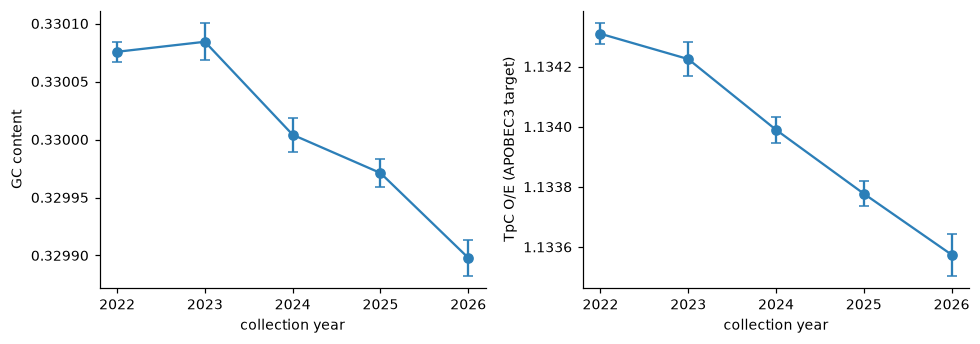

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
h["year"] = h.dec.astype(int)
for ax, col, lab in zip(axs, ["gc_content", "oe_TC"], ["GC content", "TpC O/E (APOBEC3 target)"]):
    g = h.groupby("year")[col].agg(["mean", "sem", "count"])
    g = g[g["count"] >= 20]
    ax.errorbar(g.index, g["mean"], yerr=1.96 * g["sem"], marker="o", color="#2C7FB8", capsize=3)
    ax.set_xlabel("collection year"); ax.set_ylabel(lab); ax.set_xticks(g.index)
plt.tight_layout(); fig.savefig("results/figures/mpox_time_trend.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.**

- **GC content:** the slope is about **-0.000025 per year**, which is **right where the APOBEC3 arithmetic predicts**. The 95% interval still includes zero (p = 0.18), because the signal is tiny next to the genome-to-genome noise (SD 0.0002).
- **TpC O/E:** falls by about 0.0002 per year (p = 0.005): the dinucleotide APOBEC3 edits is slowly being used up, as expected.
- **CpG O/E** also falls (p < 0.0001), which is not what APOBEC3 predicts as directly; an overall shift in which clades are sampled is the more likely cause.

**Limits (important).** The export has **no lineage column**, so this is the *all-lineages-pooled* analysis the RSV project showed to be unreliable: a later lineage replacing an earlier one can create a trend without any lineage changing (Simpson's paradox). The result is therefore exploratory. It needs lineage labels (Nextclade or the GISAID lineage field) and a re-run inside each lineage. With 55 countries the clustered errors are reasonable, but sequencing is dominated by the USA and Germany.

## 4. What this means

| Question | Answer |
|---|---|
| Does the host field offer a contrast? | **No.** 94% human; the rest is wastewater, unknown host, or about 40 animal fragments with no full genome. |
| Is mpox CpG-suppressed? | **No** (CpG O/E 1.04), so the RSV CpG story does not carry over. |
| Does the APOBEC3 signature appear? | **Weakly.** GC and TpC fall at the rate predicted, but only TpC is statistically clear, and lineage replacement is not excluded. |

**Verdict.** Mpox does not offer the sporadic-versus-sustained contrast that the host field would need. It is worth a second look only for the APOBEC3 signature, and that requires lineage labels first.